# 02 – Khám phá dữ liệu (EDA)

**Phần 1:** Phân phối biến mục tiêu `Appliances` và giá trị ngoại lệ.

**Phần 2:** Xu hướng tiêu thụ theo thời gian (giờ, ngày trong tuần, theo tuần).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import TARGET
from src.data_loader import load_raw_data
from src.visualization import save_fig, set_style

set_style()
df = load_raw_data()
y = df[TARGET]
df.shape

(19735, 29)

## Phần 1. Phân phối biến mục tiêu
### 1.1 Histogram và boxplot

Đã lưu hình: reports/figures/02_target_distribution.png


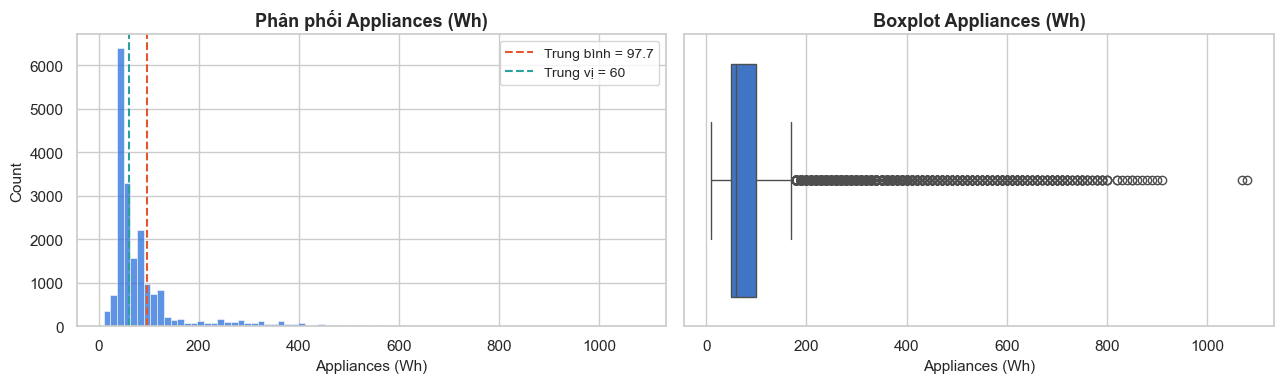

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y, bins=80, ax=axes[0])
axes[0].axvline(y.mean(), color="#e4572e", linestyle="--", label=f"Trung bình = {y.mean():.1f}")
axes[0].axvline(y.median(), color="#29a19c", linestyle="--", label=f"Trung vị = {y.median():.0f}")
axes[0].set_title("Phân phối Appliances (Wh)")
axes[0].set_xlabel("Appliances (Wh)")
axes[0].legend()

sns.boxplot(x=y, ax=axes[1])
axes[1].set_title("Boxplot Appliances (Wh)")
axes[1].set_xlabel("Appliances (Wh)")
fig.tight_layout()
save_fig(fig, "02_target_distribution")
plt.show()

In [3]:
print("Skewness:", round(y.skew(), 2))
y.quantile([0.5, 0.75, 0.9, 0.95, 0.99]).to_frame("Wh")

Skewness: 3.39


,Wh
0.50,60.0
0.75,100.0
0.90,196.0
0.95,330.0
0.99,576.6


**Nhận xét:**
- Phân phối **lệch phải rất mạnh** (skewness ≈ 3.4): phần lớn thời gian thiết bị tiêu thụ 40–100 Wh,
  nhưng có đuôi dài tới 1080 Wh.
- Trung bình (~98 Wh) lớn hơn hẳn trung vị (60 Wh) do bị các đỉnh cao kéo lên.
- 90% mẫu ≤ 196 Wh, nhưng 1% mẫu cao nhất vượt 576 Wh.

### 1.2 Giá trị ngoại lệ theo quy tắc IQR

In [4]:
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
n_out = (y > upper).sum()
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}")
print(f"Ngưỡng trên = {upper:.0f} Wh")
print(f"Số mẫu vượt ngưỡng: {n_out} ({n_out / len(y):.2%})")

Q1 = 50, Q3 = 100, IQR = 50
Ngưỡng trên = 175 Wh
Số mẫu vượt ngưỡng: 2138 (10.83%)


**Quyết định xử lý ngoại lệ:**
- Có ~10,8% mẫu vượt ngưỡng IQR (175 Wh). Tỷ lệ này **quá lớn** để coi là lỗi đo.
- Về bản chất vật lý, các giá trị này là **những lúc nhiều thiết bị cùng hoạt động** (nấu ăn, giặt, ...),
  chính là hiện tượng mô hình cần dự đoán.
- → **Không xóa** ngoại lệ ở biến mục tiêu. Thay vào đó xem xét **biến đổi log** để giảm ảnh hưởng của đuôi dài
  khi huấn luyện, và báo cáo thêm **MAE** (ít nhạy với ngoại lệ hơn RMSE).

### 1.3 Biến đổi log1p

Đã lưu hình: reports/figures/02_target_log_transform.png


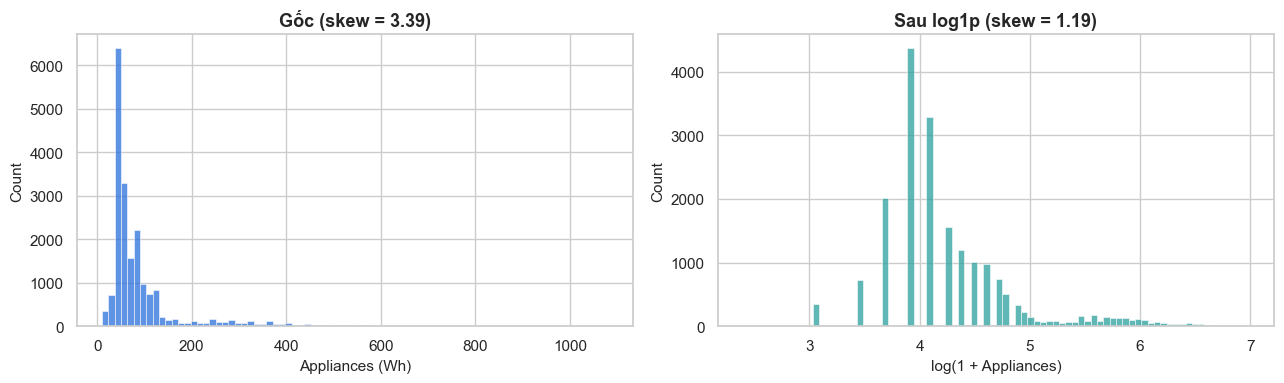

In [5]:
y_log = np.log1p(y)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(y, bins=80, ax=axes[0])
axes[0].set_title(f"Gốc (skew = {y.skew():.2f})")
axes[0].set_xlabel("Appliances (Wh)")
sns.histplot(y_log, bins=80, ax=axes[1], color="#29a19c")
axes[1].set_title(f"Sau log1p (skew = {y_log.skew():.2f})")
axes[1].set_xlabel("log(1 + Appliances)")
fig.tight_layout()
save_fig(fig, "02_target_log_transform")
plt.show()

**Nhận xét:** Sau `log1p`, độ lệch giảm từ ~3.39 xuống ~1.19 – phân phối cân đối hơn nhiều.
Nhóm sẽ thực nghiệm huấn luyện mô hình trên `log1p(Appliances)` rồi đổi ngược (`expm1`) khi đánh giá,
để metric vẫn tính trên đơn vị Wh gốc và so sánh công bằng với mô hình không dùng log.

### 1.4 Biến `lights`

In [6]:
print("Tỷ lệ lights = 0:", f"{(df['lights'] == 0).mean():.1%}")
print("Tương quan lights – Appliances:", round(df["lights"].corr(y), 3))
df["lights"].value_counts().sort_index().to_frame("số mẫu")

Tỷ lệ lights = 0: 77.3%
Tương quan lights – Appliances: 0.197


,số mẫu
lights,
0,15252
10,2212
20,1624
30,559
40,77
50,9
60,1
70,1


`lights` bằng 0 trong ~77% thời gian và chỉ nhận vài giá trị rời rạc (0, 10, 20, ...). Tương quan với
`Appliances` dương nhưng yếu (~0.2). Đây là tín hiệu "có người đang ở nhà/hoạt động", nên vẫn giữ làm đặc trưng.